# 04. 수동 Expert 104개 절삭 및 검증

정렬 모델의 각 층 ordered ID 0–103을 유지합니다. 바이트 검증은 추론 동등성이나 품질을 보장하지 않습니다.
이전에 저장된 셀 출력은 이전 환경 기록이며 현재 A100의 실행 결과가 아닙니다.
모든 실행 단계는 기본적으로 꺼져 있습니다.

In [1]:
from pathlib import Path
import sys, subprocess
ROOT = Path.cwd().resolve()
if ROOT.name == 'ipynb': ROOT = ROOT.parent
assert (ROOT / 'moe_prune').is_dir()
sys.path.insert(0, str(ROOT))
from tools import manual104 as work

INSTALL_DEPENDENCIES = False
PREPARE_GRADER = False
PREPARE_ENGINE = False
BUILD_ENGINE = False
RUN_VERIFY_FILES = False
RUN_EXPORT = False
RUN_COMPARISON = False
RUN_GENERATION = False
RUN_GRADING = False
RUN_PLOTS = False

# 기본은 LCB 첫 두 문제, 전체 100문항은 tuple(range(1, 101))로 명시적으로 변경.
INDICES = (1, 2)
COMPARISON_DIR = work.RUN / 'comparison-001'
GENERATION_DIR = work.RUN / 'generation-001'
ORDERED_MODEL = work.ORDERED
PRUNED_MODEL = work.MODEL
RESULT_ROOT = work.EXPORT_RUN
REEXPORT_MODEL = PRUNED_MODEL
REEXPORT_DIR = RESULT_ROOT
DEFAULT_CONFIG = work.config03()
print({'seed': DEFAULT_CONFIG['seed'],
       'context_requested': DEFAULT_CONFIG['context_size'],
       'max_tokens': DEFAULT_CONFIG['max_tokens'],
       'ram_usage_warn_fraction': DEFAULT_CONFIG['ram_usage_warn_fraction'],
       'vram_usage_warn_fraction': DEFAULT_CONFIG['vram_usage_warn_fraction']})
print({'ordered_model_present': work.ORDERED.is_file(), 'export_present': (work.EXPORT_RUN / 'export-manifest.json').is_file(), 'engine_present': work.ENGINE.is_file()})

{'seed': 42, 'context_requested': 65535, 'context_actual_required': 65536, 'max_tokens': 32768, 'engine_batch': 64, 'engine_ubatch': 64, 'gpu_layers': 12, 'offload_kqv': True, 'system_ram_cap': 0.7, 'vram_cap': 0.97, 'commit_reserve_gib': 4.0, 'vram_workspace_gib': 1.0}
{'ordered_model_present': True, 'export_present': True, 'engine_present': True}


## Colab 환경 준비

설치·CUDA 빌드·공식 채점기 준비는 설정의 플래그를 켤 때만 실행합니다.

In [ ]:
if INSTALL_DEPENDENCIES:
    subprocess.run([sys.executable, '-m', 'pip', '--isolated', 'install',
                    '-r', str(ROOT / 'requirements-research.txt')], check=True)
if PREPARE_GRADER:
    from moe_prune.benchmark_data import prepare_grader
    prepare_grader(ROOT)
if PREPARE_ENGINE:
    command = [sys.executable, str(ROOT / 'tools/native/prepare.py'),
               '--backend', 'cuda', '--gpu-target', '80']
    if BUILD_ENGINE:
        command.append('--execute')
    subprocess.run(command, cwd=ROOT, check=True)
if not any((INSTALL_DEPENDENCIES, PREPARE_GRADER, PREPARE_ENGINE)):
    print('환경 준비를 실행하지 않았습니다.')


## 모델 확인

RUN_VERIFY_FILES=True일 때 전체 파일 해시를 재검증합니다.
RUN_EXPORT=True는 기본 출력 모델과 manifest가 없을 때 생성합니다.
기존 파일을 덮어쓰지 않습니다. 별도 사본 경로는 생성할 수 있지만,
후속 생성은 work.MODEL과 work.EXPORT_RUN의 manifest를 사용합니다.

In [2]:
from moe_prune.gguf import GGUF, sha256
manifest_path = RESULT_ROOT / 'export-manifest.json'
if manifest_path.is_file():
    import json
    export_info = json.loads(manifest_path.read_text(encoding='utf-8'))
    print({k: export_info.get(k) for k in ('source','output','source_bytes','output_bytes','savings_bytes','output_sha256','file_validation_status','inference_status','quality_status')})
    if PRUNED_MODEL.is_file():
        architecture = GGUF(PRUNED_MODEL).architecture()
        actual_bytes = PRUNED_MODEL.stat().st_size
        assert architecture == (list(range(30)),104,8) and actual_bytes == export_info['output_bytes'], '모델 구조 또는 크기 불일치'
        print({'architecture': architecture, 'actual_bytes': actual_bytes})
        if RUN_VERIFY_FILES:
            assert sha256(PRUNED_MODEL) == export_info['output_sha256'], '절삭 모델 해시 불일치'
            assert sha256(ORDERED_MODEL) == work.ORDERED_SHA, '정렬 원본 모델 해시 불일치'
            print('두 모델 SHA-256 검증 통과')
else:
    print('아직 검증된 104 모델 manifest가 없습니다.')

{'source': 'D:\\Repos\\wemakemodel\\models\\gemma-4-26B-A4B-it-UD-IQ4_NL-lcb100-activity-ordered.gguf', 'output': 'D:\\Repos\\wemakemodel\\models\\gemma-4-26B-A4B-it-UD-IQ4_NL-lcb100-activity-ordered-e104.gguf', 'source_bytes': 13613037280, 'output_bytes': 11538949024, 'savings_bytes': 2074088256, 'output_sha256': 'd4f395700b4a1739007c6214a5c256e73bc4f48c71b2ee7528dafa76be0652f2', 'file_validation_status': 'passed', 'inference_status': 'unverified', 'quality_status': 'unverified'}
{'architecture': ([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29], 104, 8), 'actual_bytes': 11538949024}


## 공통 실행 조건

seed 42, context 요청 65,535, 최대 32,768 토큰, thinking, temperature 1.0,
top-p 0.95, top-k 64, Q8/Q8 KV, Flash Attention을 유지합니다.
전체 GPU 적재를 요청하고 RAM 80%·VRAM 97% 초과는 경고합니다.
경고 후 실행을 계속하므로 메모리 부족으로 인한 종료를 방지하지는 못합니다.
기록된 사용량은 표본이며 정확한 물리 최대치가 아닙니다.

In [3]:
if RUN_EXPORT:
    export_result = work.export(source=ORDERED_MODEL, output=REEXPORT_MODEL, run=REEXPORT_DIR, mapping_path=work.MAP)
    print(export_result['output_sha256'], export_result['file_validation_status'])

## 마스크 원본과 물리 104 비교
RUN_COMPARISON=True로 켜는 별도 수동 단계입니다. 입력별 수 분 이상 걸릴 수 있습니다. 정렬된 128 전문가 모델의 각 층에서 0–103만 허용한 결과와 물리 104 모델 logits를 비교합니다. 각 쪽의 전체 라우팅 기록을 검증하며 허용 오차는 atol=rtol=1e-4입니다. 결과는 제한된 입력의 관찰이며 실패해도 자동 생성이나 후속 단계가 실행되지 않습니다.

In [4]:
if RUN_COMPARISON:
    comparison = work.compare_masked(INDICES, COMPARISON_DIR)
    print(comparison)

## 선택 문항 생성과 계측
RUN_GENERATION=True로 켭니다. 각 문제 생성에는 수십 분 이상, 전체 100문항은 여러 시간이 걸릴 수 있습니다. 단일 상주 세션에서 문제별 KV 및 sampler를 초기화합니다. 실제 context/FA/KV/샘플링 로그와 104개 전문가 ID 범위·중복·누락·유한 가중치를 확인합니다. 계측 기록 원본과 압축본을 보존합니다. 표본 GPU 메모리는 정확한 물리 최대치가 아니며 계측이 속도에 영향을 줍니다.

In [5]:
if RUN_GENERATION:
    work.run_generation(INDICES, GENERATION_DIR)

1/2 livecodebench:3674 완료
2/2 livecodebench:3677 완료


## 공식 채점

RUN_GRADING=True로 켭니다. 생성 및 추론 프로세스 종료 후 채점합니다.
생성 코드는 Colab 사용자 권한의 별도 프로세스에서 실행되며 보안 격리되지 않습니다.
환경 오류는 오답과 구분합니다.

In [6]:
if RUN_GRADING:
    work.grade(GENERATION_DIR)

## 전문가 선택 기록
RUN_PLOTS=True로 기존 기록을 집계해 그림을 생성합니다. 입력과 생성 단계 전체 이벤트를 합칩니다. 정확한 선택 0은 검정, 양수는 흰색부터 빨강, 미관측은 회색이며 빨강은 해당 문제에서 관측된 최대 빈도입니다. 선택 빈도는 기여도나 의미상 전문성을 뜻하지 않습니다. 레이어마다 ID는 별개이며 export manifest에 원래 ID 대응을 보존합니다.

In [7]:
if RUN_PLOTS:
    print(work.render_profiles(GENERATION_DIR))

D:\Repos\wemakemodel\runs\gemma4-ordered-e104-001\generation-001\visualizations


## 기존 결과 보기
저장된 결과만 읽습니다. 완료되지 않은 채점은 대기 중으로 표시하며 계측 속도와 GPU 사용량은 표본치입니다.

| 문제 | 판정 | 생성 토큰 | 시간(초) | 생성 tok/s | RAM GiB | GPU 표본 GiB |
|---|---|---:|---:|---:|---:|---:|
| 001 livecodebench:3674 | 통과 | 10840 | 1203.01 | 9.10 | 15.60 | 8.46 |
| 002 livecodebench:3677 | 통과 | 13921 | 1623.06 | 8.61 | 15.72 | 8.46 |

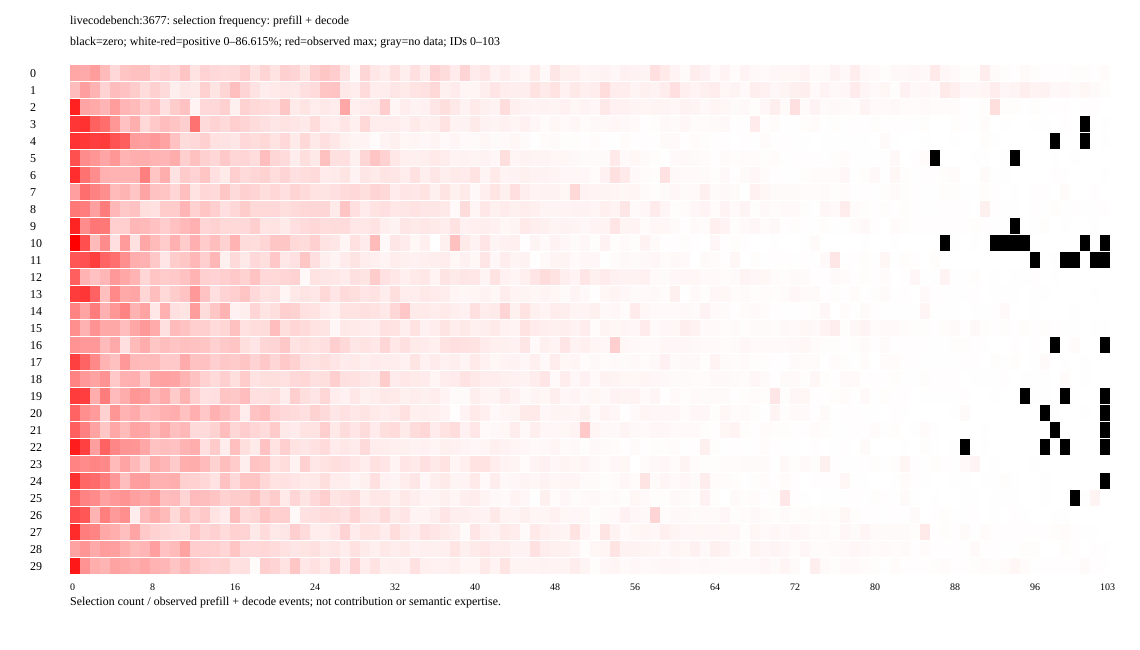

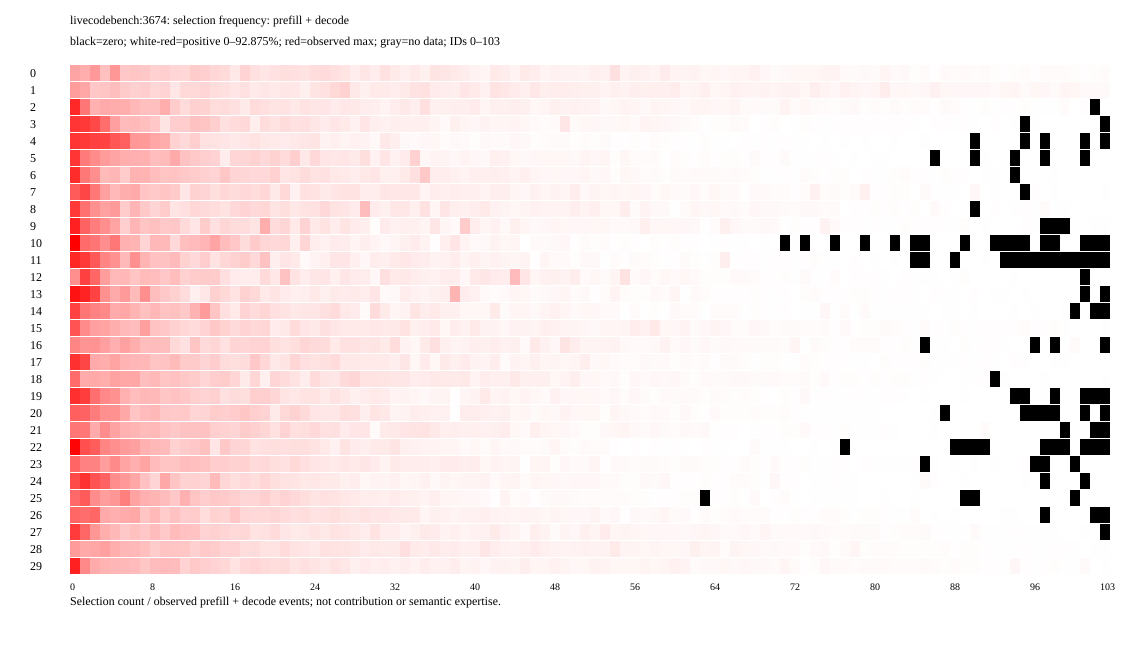

In [8]:
import json
from IPython.display import display, SVG, Markdown
status_path = GENERATION_DIR / 'status.json'
if not status_path.exists():
    print('생성 결과: 대기 중')
else:
    status = json.loads(status_path.read_text(encoding='utf-8'))
    grade_path = GENERATION_DIR / 'grading/summary.json'
    grades = json.loads(grade_path.read_text(encoding='utf-8'))['cases'] if grade_path.is_file() else []
    grade_by_number = {x['number']: x for x in grades}
    table = ['| 문제 | 판정 | 생성 토큰 | 시간(초) | 생성 tok/s | RAM GiB | GPU 표본 GiB |', '|---|---|---:|---:|---:|---:|---:|']
    def fmt(value, divisor=1):
        return '미측정' if value is None else f'{value/divisor:.2f}'
    for number in status.get('indices', []):
        answer_path = GENERATION_DIR / 'answers' / f'{number:03d}.json'
        if not answer_path.is_file():
            table.append(f'| {number:03d} | 생성 대기 | 미측정 | 미측정 | 미측정 | 미측정 | 미측정 |'); continue
        answer = json.loads(answer_path.read_text(encoding='utf-8'))
        grade = grade_by_number.get(number, {})
        result = '통과' if grade.get('passed') is True else '실패' if grade.get('passed') is False else '채점 대기 또는 환경 오류'
        measurement = answer.get('measurement', {})
        gpu = measurement.get('os_gpu_memory') or {}
        timing = answer.get('timings') or {}
        table.append(f"| {number:03d} {answer['id']} | {result} | {len(answer.get('token_ids', []))} | {fmt(measurement.get('wall_s'))} | {fmt(timing.get('decode_tokens_s'))} | {fmt(measurement.get('peak_process_tree_rss_bytes'), 1024**3)} | {fmt(gpu.get('peak_bytes'), 1024**3)} |")
    display(Markdown('\n'.join(table)))
    figures = GENERATION_DIR / 'visualizations'
    if figures.is_dir():
        for path in sorted(figures.glob('*.svg')): display(SVG(filename=str(path)))